# 06 · Support Vector Machines (handbook 3.5.4)
`SVC` training time grows roughly with the square of the number of rows, so on 115k rows it would take hours.
- **Linear SVM:** `LinearSVC` (same model, much faster solver) on the full training set.
- **Non-linear SVM (RBF):** `SVC` on a stratified 15k sample, nested grid over (C, gamma).

SVMs give no probabilities, so no AUC is reported for them.

In [1]:
import sys
from pathlib import Path

# find the project root (the folder that contains src/dsc_utils.py) and import the shared helpers
root = Path.cwd()
while not (root / "src" / "dsc_utils.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dsc_utils import *

d = load_prepared()
x_train, x_val, x_test = d["x_train"], d["x_val"], d["x_test"]
y_train, y_val, y_test = d["y_train"], d["y_val"], d["y_test"]
feature_names = d["feature_names"]
print("train", x_train.shape, "| val", x_val.shape, "| test", x_test.shape)
import time
from sklearn.svm import LinearSVC, SVC

train (114844, 1711) | val (28712, 1711) | test (35890, 1711)


## Linear SVM: grid over C

0.0009765625 0.3935
0.00390625 0.4135
0.015625 0.4275
0.0625 0.4334
0.25 0.4356
1 0.4381
4 0.4368
Optimal C: 1
{'model': 'SVM (linear)', 'accuracy': 0.4685, 'macro_F1': 0.436, 'ordinal_MAE': 0.8351, 'within_one': 0.7942, 'EFG_recall': 0.7402}


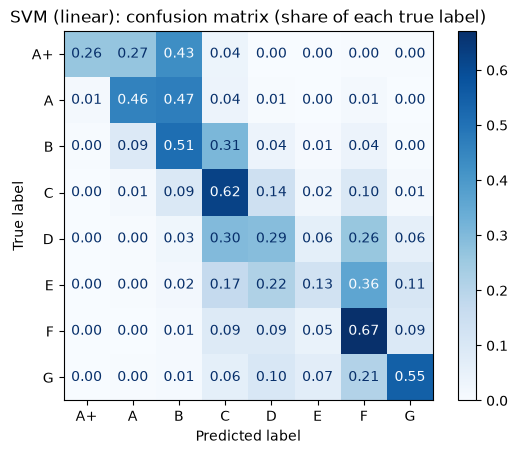

In [2]:
C = [2**p for p in range(-10, 3, 2)]
f1_val = []
for c in C:
    m = LinearSVC(C=c, dual="auto", max_iter=5000).fit(x_train, y_train)
    f1_val.append(macro_f1(y_val, m.predict(x_val)))
    print(c, round(f1_val[-1], 4))
c_opt = C[int(np.argmax(f1_val))]
print("Optimal C:", c_opt)

SVM_lin = LinearSVC(C=c_opt, dual="auto", max_iter=5000).fit(x_train, y_train)
evaluate("SVM (linear)", SVM_lin, x_test, y_test)
save_model(SVM_lin, "SVM_linear")

## Non-linear SVM (RBF kernel): nested grid over (C, gamma) on a sample

In [3]:
xs, ys = stratified_sample(x_train, y_train, 15000)
xv, yv = stratified_sample(x_val, y_val, 5000)
results = []
for c in [1, 10, 100]:
    for g in ["scale", 0.001, 0.01]:
        t = time.time()
        m = SVC(C=c, kernel="rbf", gamma=g).fit(xs, ys)
        results.append((macro_f1(yv, m.predict(xv)), c, g))
        print(c, g, round(results[-1][0], 4), f"{time.time() - t:.0f}s")
_, c_opt, g_opt = max(results, key=lambda r: r[0])
print("Optimal C:", c_opt, "| gamma:", g_opt)

1 scale 0.4256 195s
1 0.001 0.3669 102s
1 0.01 0.4283 84s
10 scale 0.4957 88s
10 0.001 0.4298 62s
10 0.01 0.4927 66s
100 scale 0.4733 80s
100 0.001 0.4786 67s
100 0.01 0.4798 75s
Optimal C: 10 | gamma: scale


{'model': 'SVM (RBF, 15k sample)', 'accuracy': 0.5122, 'macro_F1': 0.497, 'ordinal_MAE': 0.712, 'within_one': 0.8422, 'EFG_recall': 0.7207}


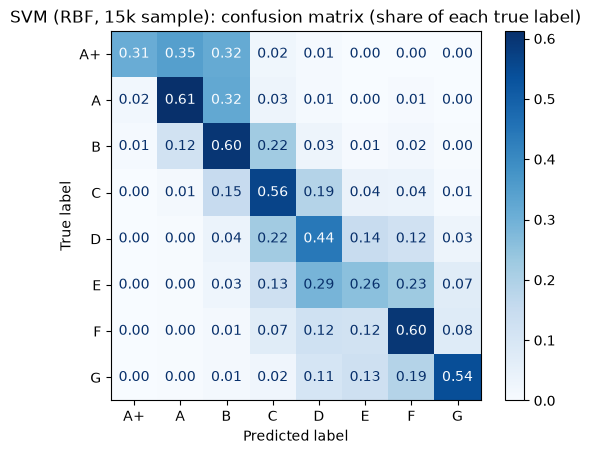

In [4]:
SVM_rbf = SVC(C=c_opt, kernel="rbf", gamma=g_opt).fit(xs, ys)        # trained on the 15k sample
evaluate("SVM (RBF, 15k sample)", SVM_rbf, x_test, y_test)
save_model(SVM_rbf, "SVM_rbf")